# Sesión 2 · Reembolsos con aprobación humana (Human-in-the-loop)
**21 de octubre de 2026 · Caso resuelto · Guía paso a paso · LangGraph + Groq · Colab**

> 🧠 **Idea central de la sesión:** un agente puede **proponer**; solo una **persona** puede **autorizar**. Y esa autorización debe ocurrir dentro del flujo, con una **pausa real y reanudable**, no con un texto que diga “PENDIENTE”.

### 🎯 Al terminar podrás
1. Pausar un grafo con `interrupt()` y **reanudarlo** con `Command(resume=...)` usando el mismo `thread_id`.
2. Explicar el papel del **checkpointer** (`InMemorySaver`): dónde “espera” el caso mientras nadie decide.
3. Distinguir **elegibilidad** (la decide la política, en Python) de **autorización** (la decide una persona).
4. Validar con **Pydantic** la propuesta del agente **y** la respuesta de la persona.
5. Probar los tres desenlaces: **espera**, **aprobación** y **rechazo**, además de entradas inválidas.

> ⚠️ Todos los datos y políticas son **ficticios**. **No se realiza ningún pago**: el “reembolso” es un registro en memoria.

### 📦 El caso
| Dato | Valor |
|---|---|
| Pedido | `PED-1042` |
| Motivo | Producto defectuoso reportado por el cliente |
| Días desde la entrega | 5 |
| Valor | $450.000 COP |
| Evidencia del defecto | **Ninguna independiente**: solo el reporte del cliente |

### 📜 Política didáctica
| Regla | Valor | Quién la aplica |
|---|---|---|
| Plazo para reportar defectos | 15 días | **Python** (`ruta_propuesta`) |
| Umbral que exige aprobación humana | $300.000 COP | Informativo en el payload |
| **Regla de esta clase** | **Toda** propuesta elegible pasa por una persona, incluso bajo el umbral | Arquitectura del grafo |

🧠 La regla de clase existe para no confundir **elegible** (“cumple la política”) con **autorizado** (“una persona lo aprobó”).

### 🧭 Cómo recorrer este notebook
Este caso está **completamente resuelto**: no hay código por completar. Lo ejecutamos y lo explicamos juntos.

1. Ejecuta las celdas **en orden, una por una**. Evita *Ejecutar todo*: la gracia es **observar la pausa** antes de decidir.
2. Mantén `MODO_SIMULADO = True` en la explicación inicial: no necesitas clave ni LLM.
3. Cada paso tiene: **Qué hace**, **📤 Salida esperada** y **🤔 Pausa para comprender**.
4. Cuando el grafo se pausa, **la celda termina**: el caso queda guardado en el checkpointer, no “colgado” ejecutándose.

| Paso | Qué haces | Celda clave |
|---|---|---|
| 1 | Instalar dependencias | `%pip install` |
| 2 | Configurar, definir contratos y probarlos | `Analisis`, `Propuesta`, `DecisionHumana` |
| 3 | Leer y probar los tres agentes | `atencion`, `politicas`, `supervisor` |
| 4 | Construir la revisión humana, las salidas y el grafo | `interrupt()`, `InMemorySaver` |
| 5 | Visualizar el grafo | `draw_mermaid_png()` |
| 6 | Iniciar una solicitud y **observar la pausa** | `app.invoke(...)` |
| 7 | Inspeccionar el checkpoint | `app.get_state(config)` |
| 8 | **Decidir como persona** y reanudar | `Command(resume=...)` |
| 9 | Comprobar qué código se repitió | contador de ejecuciones |
| 10 | Pruebas automatizadas | tabla de 9 pruebas |
| 11 | Transferir al reto de pagos | discusión |

🔣 **Convenciones:** 🧠 concepto · ▶️ ejecutar · 📥 entrada · 📤 salida esperada · 🤔 pausa · ⚠️ cuidado

### 🗺️ Arquitectura del flujo
```
START ─► Atención ─► Políticas ─► Supervisor ─► ¿elegible y "reembolsar"? ──no──► Cierre ─► END
           (LLM)       (LLM)        (LLM)                 │ sí
                                                          ▼
                                                 Revisión humana ⏸ interrupt()
                                                 (el grafo se PAUSA y guarda
                                                  su estado en el checkpointer)
                                                          │ Command(resume=decisión)
                                                          ▼
                                                 ¿la persona aprobó? ──no──► Cierre ─► END
                                                          │ sí
                                                          ▼
                                                 Registro (simulado) ─► END
```

| Nodo | Lee | Escribe | LLM | Efecto externo |
|---|---|---|---|---|
| `atencion` | `caso` | `atencion` | Sí | — |
| `politicas` | `caso`, `atencion` | `politicas` | Sí | — |
| `supervisor` | `caso`, `atencion`, `politicas` | `propuesta` | Sí | — |
| `revision_humana` | `caso`, `politicas`, `propuesta` | `decision_humana` | **No** | **Pausa** el grafo |
| `registro` | `caso`, `propuesta`, `decision_humana` | `resultado` | No | Escribe en `REGISTRO` (simulado) |
| `cierre` | todo | `resultado`, `motivo_cierre` | No | — |

| Decisión | La toma | Cómo |
|---|---|---|
| ¿Es elegible? | **Python** | `ruta_propuesta`: plazo y recomendación |
| ¿Se autoriza? | **Una persona** | `interrupt()` + `Command(resume=...)` |
| ¿Se registra? | **Python** | `ruta_decision` + comprobaciones en `registrar` |

### 🐍 Mini-glosario de Python usado en este notebook
Si una celda te resulta difícil, casi siempre es por una de estas construcciones:

| Sintaxis | Ejemplo | Qué significa |
|---|---|---|
| Copiar y modificar un diccionario | `{**CASO, "pedido": "X"}` | Crea un dict **nuevo** con todo lo de `CASO`, pero cambia (o agrega) `pedido`. `CASO` no se modifica |
| Comprensión de diccionario | `{k: v for k, v in d.items() if k != "motivo"}` | Construye un dict nuevo con los pares de `d`, **excepto** `motivo` |
| `dict.get(clave, defecto)` | `contador.get(hilo, 0)` | Devuelve el valor si existe; si no, devuelve `0` (sin error) |
| `dict.setdefault(clave, valor)` | `REGISTRO.setdefault(pedido, {...})` | Guarda el valor **solo si la clave no existe**; si ya existe, no la toca |
| f-string | `f"Monto {m} COP"` | Texto con valores insertados entre llaves |
| Anotaciones de tipo | `def f(e: Estado) -> dict:` | Documentan qué entra y qué sale; Python **no** las hace cumplir (Pydantic sí) |
| `Literal[...]` | `Literal["aprobar", "rechazar"]` | Solo se aceptan esos valores exactos |
| `TypedDict` | `class Estado(TypedDict)` | Describe las claves que tendrá un diccionario; no valida en tiempo de ejecución |
| `BaseModel` (Pydantic) | `class Propuesta(BaseModel)` | Clase que **valida** los datos al crearse y lanza `ValidationError` si no cumplen |
| `assert condición, "mensaje"` | `assert pausa.get("__interrupt__")` | Si la condición es falsa, se detiene con `AssertionError`. Útil en pruebas |
| `try / except / else` | ver paso 10 | `try` intenta; `except` atrapa un error esperado; `else` se ejecuta **solo si no hubo error** |
| `raise` | `raise ValueError("...")` | Lanza un error a propósito para detener el flujo |
| Desempaquetar argumentos | `create(**extra)` | Pasa las claves del dict `extra` como argumentos con nombre |
| Funciones como valores | `[("atencion", atencion), ...]` | Una función se puede guardar en una lista y llamar después |
| `uuid4().hex` | `"reembolso-" + uuid4().hex` | Genera un identificador aleatorio único |

## Paso 1 · ▶️ Instalar dependencias
**Qué hace:** instala LangGraph (grafo, `interrupt`, checkpointer), Pydantic (contratos), el cliente de Groq, pandas (tablas) y python-dotenv (lee la clave de `.env` en local). No crea agentes ni ejecuta nada.

**📤 Salida esperada:** sin errores (puede no imprimir nada). Si Colab pide reiniciar el entorno, hazlo antes de continuar.

🤔 **¿Instalar una biblioteca equivale a ejecutar el grafo?** No.

In [51]:
%pip install -q "langgraph>=1,<2" "pydantic>=2,<3" "groq>=0.30" "pandas>=2" "python-dotenv>=1,<2"

## Paso 2 · Configuración, contratos y datos

### 2.1 ▶️ Configuración y función `consultar()`
**Qué hace:** elige el modo y define `consultar()`, el **único punto de contacto con el LLM**.

| Modo | `MODO_SIMULADO` | Qué devuelve `consultar()` |
|---|---|---|
| Simulado | `True` | La respuesta fija (`simulado`) que cada agente trae escrita, **validada** con el mismo esquema |
| Real | `False` | Pide a Groq un JSON con ese esquema y lo valida con Pydantic |

`consultar(rol, contexto, esquema, simulado)`:
| Parámetro | Qué es |
|---|---|
| `rol` | Instrucción de sistema del agente |
| `contexto` | Diccionario con la información que el agente puede ver (se envía como JSON) |
| `esquema` | Clase Pydantic que la respuesta **debe** cumplir |
| `simulado` | Respuesta fija para el modo simulado |

**📤 Salida esperada:** `Modo: simulado | Modelo: openai/gpt-oss-120b`

> ⚠️ En modo real, si el modelo devuelve algo que no cumple el esquema, se lanza `ValidationError` y **el flujo se detiene antes de la autorización**. Nunca se “arregla” la respuesta inventando datos.

#### 📖 Lectura guiada de la celda
| Fragmento | Qué hace |
|---|---|
| `from langgraph.types import interrupt, Command` | `interrupt` pausa el grafo; `Command` sirve para reanudarlo con la respuesta de la persona |
| `from langgraph.checkpoint.memory import InMemorySaver` | El “cajón” donde se guarda el estado del grafo mientras está en pausa |
| `MODO_SIMULADO = True` | Interruptor: `True` usa respuestas fijas; `False` llama a Groq |
| `os.getenv("GROQ_MODEL", "openai/gpt-oss-120b")` | Lee una variable de entorno; si no existe, usa el valor por defecto |
| `load_dotenv()` | Carga las variables de `.env` (raíz del repositorio) si existe; en Colab no encuentra el archivo y no hace nada |
| `if not MODO_SIMULADO: ...` | Solo en modo real se importa Groq y se lee la clave: primero del entorno (`.env`) y, si no está, de los Secrets de Colab |
| `_solo_json(texto)` | Recorta la respuesta del modelo para quedarse con el objeto `{ ... }` aunque venga rodeado de texto o de ```` ```json ```` |
| `re.search(r"\{.*\}", texto, flags=re.DOTALL)` | Expresión regular: busca desde la primera `{` hasta la última `}`; `DOTALL` permite que cruce varias líneas |
| `esquema.model_validate(simulado)` | Valida un **dict** con el contrato Pydantic |
| `esquema.model_json_schema()` | Convierte el contrato en un esquema JSON que se envía al modelo para que sepa qué formato devolver |
| `esquema.model_validate_json(texto)` | Valida un **texto JSON** con el contrato |
| `.model_dump()` | Convierte el objeto validado de vuelta a un dict simple (lo que se guarda en el estado) |
| `extra = {...} if "gpt-oss" in MODEL else {}` y `**extra` | Agrega `reasoning_effort` solo si el modelo lo soporta |

In [53]:
import json, os, re                      # json: texto ↔ dict · os: variables de entorno · re: expresiones regulares
from uuid import uuid4                   # identificadores únicos para pedidos y solicitudes
from typing import TypedDict, Literal    # tipos para describir el estado y valores permitidos

import pandas as pd                      # tablas para mostrar resultados de pruebas
from pydantic import BaseModel, Field, ConfigDict, ValidationError   # contratos de datos
from langgraph.graph import StateGraph, START, END                  # piezas del grafo
from langgraph.types import interrupt, Command            # interrupt = pausar · Command = reanudar
from langgraph.checkpoint.memory import InMemorySaver     # guarda el estado del grafo en memoria
from IPython.display import display, Image                # mostrar tablas e imágenes en el notebook
from dotenv import load_dotenv                            # lee .env en local (en Colab no hace nada)

# ── 1. Modo y modelo ─────────────────────────────────────────────────────────
MODO_SIMULADO = True     # True: sin clave ni LLM · False: Groq real
load_dotenv()            # carga .env si existe, antes de leer GROQ_MODEL y GROQ_API_KEY
MODEL = os.getenv("GROQ_MODEL", "openai/gpt-oss-120b")   # usa la variable de entorno o este valor

# ── 2. Cliente de Groq (solo en modo real) ───────────────────────────────────
client = None                                    # en modo simulado no hay cliente
if not MODO_SIMULADO:
    from groq import Groq                        # se importa solo si se va a usar
    key = os.getenv("GROQ_API_KEY")              # en local viene de .env
    if not key:
        try:
            from google.colab import userdata    # acceso a los Secrets de Colab
            key = userdata.get("GROQ_API_KEY")
        except ImportError:
            pass                                 # fuera de Colab este módulo no existe
    if not key:
        raise ValueError("Configura GROQ_API_KEY en .env o en los Secrets de Colab (con acceso del notebook activado).")
    client = Groq(api_key=key)                   # objeto que hace las llamadas a la API


def _solo_json(texto: str) -> str:
    # Algunos modelos responden "Aquí está: ```json {...} ```". Nos quedamos solo con { ... }.
    coincidencia = re.search(r"\{.*\}", texto or "", flags=re.DOTALL)   # de la primera { a la última }
    return coincidencia.group(0) if coincidencia else (texto or "")     # si no hay llaves, se devuelve tal cual


def consultar(rol: str, contexto: dict, esquema: type[BaseModel], simulado: dict) -> dict:
    # Devuelve un dict que CUMPLE `esquema`, o lanza ValidationError si no lo cumple.
    if MODO_SIMULADO:
        # La respuesta fija TAMBIÉN pasa por el contrato: el flujo se prueba igual que en modo real.
        return esquema.model_validate(simulado).model_dump()

    # Solo los modelos gpt-oss aceptan reasoning_effort; para otros, `extra` queda vacío.
    extra = {"reasoning_effort": "low"} if "gpt-oss" in MODEL else {}
    respuesta = client.chat.completions.create(
        model=MODEL, temperature=0, **extra,     # **extra "despliega" el dict como argumentos
        messages=[
            # Mensaje de sistema: el rol + la prohibición + el formato exacto (esquema JSON del contrato)
            {"role": "system", "content":
                rol + " No inventes evidencia ni autorización. Devuelve solo JSON con este esquema: "
                + json.dumps(esquema.model_json_schema(), ensure_ascii=False)},
            # Mensaje de usuario: el contexto que el agente puede ver, convertido a texto JSON
            {"role": "user", "content": json.dumps(contexto, ensure_ascii=False)},
        ])
    texto = respuesta.choices[0].message.content           # texto devuelto por el modelo
    return esquema.model_validate_json(_solo_json(texto)).model_dump()   # validar y convertir a dict

print("Modo:", "simulado" if MODO_SIMULADO else "Groq real", "| Modelo:", MODEL)

Modo: Groq real | Modelo: openai/gpt-oss-120b


### 2.2 ▶️ Contratos, estado y datos del caso
🧠 Hay **tres contratos**, uno por cada tipo de información que cruza una frontera de confianza:

| Contrato | Lo produce | Campos y reglas |
|---|---|---|
| `Analisis` | Agentes de atención y políticas | `resumen` (no vacío) · `evidencias` (≥ 1) · `incertidumbres` (≥ 1) |
| `Propuesta` | Supervisor | `recomendacion` ∈ {`reembolsar`, `solicitar_informacion`} · `monto_cop` entero ≥ 0 (**estricto**: `"450000"` como texto no vale) · `justificacion` |
| `DecisionHumana` | **La persona** | `decision` ∈ {`aprobar`, `rechazar`} · `revisor` · `motivo` |

`extra="forbid"`: cualquier campo no declarado (por ejemplo `"autorizado": true` inventado por un LLM) **se rechaza**.

🧠 Que `incertidumbres` sea obligatoria fuerza a los agentes a **declarar lo que no saben** (aquí: el defecto no está verificado).

`Estado` es la información compartida entre nodos durante una solicitud; **no es una base de datos**. `total=False` permite que los campos aparezcan a medida que los nodos los escriben.

**📤 Salida esperada:** `Contratos y datos listos.`

🤔 **¿Una propuesta que cumple el esquema es necesariamente verdadera?** No: el contrato valida su **forma**, no su **veracidad**.

#### 📖 Lectura guiada de la celda
| Fragmento | Qué hace |
|---|---|
| `class Analisis(BaseModel):` | Define un contrato: al crear un `Analisis`, Pydantic revisa cada campo |
| `model_config = ConfigDict(extra="forbid")` | Prohíbe campos no declarados |
| `Field(min_length=1)` | En un texto: no puede ser vacío · en una lista: al menos un elemento |
| `Field(ge=0, strict=True)` | `ge` = *greater or equal* (≥ 0) · `strict` = no convierte `"450000"` a número |
| `Literal["reembolsar", "solicitar_informacion"]` | Solo esos dos textos son válidos |
| `class Estado(TypedDict, total=False)` | Describe las claves del estado; `total=False` = ninguna es obligatoria desde el inicio |
| `CASO = {...}` / `POLITICA = {...}` | Datos ficticios de entrada; son dicts normales de Python |

In [54]:
class Analisis(BaseModel):
    model_config = ConfigDict(extra="forbid")          # campos no declarados → error
    resumen: str = Field(min_length=1)
    evidencias: list[str] = Field(min_length=1)        # al menos una evidencia citada
    incertidumbres: list[str] = Field(min_length=1)    # obliga a declarar lo que NO se sabe

class Propuesta(BaseModel):
    model_config = ConfigDict(extra="forbid")
    recomendacion: Literal["reembolsar", "solicitar_informacion"]   # nunca "aprobado"
    monto_cop: int = Field(ge=0, strict=True)          # entero, sin conversión desde texto
    justificacion: str = Field(min_length=1)

class DecisionHumana(BaseModel):
    model_config = ConfigDict(extra="forbid")
    decision: Literal["aprobar", "rechazar"]
    revisor: str = Field(min_length=1)                 # nombre declarado (NO es autenticación)
    motivo: str = Field(min_length=1)                  # la decisión debe justificarse

class Estado(TypedDict, total=False):
    caso: dict             # entrada: datos del pedido
    atencion: dict         # Analisis del agente de atención
    politicas: dict        # Analisis del agente de políticas
    propuesta: dict        # Propuesta del supervisor
    decision_humana: dict  # DecisionHumana validada
    resultado: str         # REEMBOLSO_SIMULADO_REGISTRADO | CERRADO_SIN_REEMBOLSO
    motivo_cierre: str     # por qué se cerró sin reembolso

# Datos ficticios del caso y de la política
CASO = {"pedido": "PED-1042", "monto_cop": 450000, "dias_desde_entrega": 5,
        "solicitud": "El cliente reporta un producto defectuoso y pide devolución"}
POLITICA = {"plazo_dias": 15, "umbral_aprobacion_cop": 300000}

print("Contratos y datos listos.")

Contratos y datos listos.


### 2.3 ▶️ Probar los contratos: entrada → salida esperada
Antes de conectar agentes, comprobamos que los contratos rechazan lo que deben rechazar.

| # | 📥 Entrada | 📤 Salida esperada |
|---|---|---|
| 1 | `Propuesta` correcta | ✅ válida |
| 2 | `monto_cop="450000"` (texto) | ❌ `int_type` (modo estricto) |
| 3 | `monto_cop=-1` | ❌ `greater_than_equal` |
| 4 | `recomendacion="aprobar"` | ❌ `literal_error`: el supervisor **no puede** aprobar |
| 5 | Campo extra `autorizado=True` | ❌ `extra_forbidden` |
| 6 | `DecisionHumana` con `decision="tal vez"` | ❌ `literal_error` |
| 7 | `DecisionHumana` sin `motivo` | ❌ `missing` |
| 8 | `Analisis` con `incertidumbres=[]` | ❌ `too_short` |

#### 📖 Lectura guiada de la celda
| Fragmento | Qué hace |
|---|---|
| `PROPUESTA_OK`, `DECISION_OK` | Ejemplos válidos que sirven de base para crear variantes inválidas |
| `{**PROPUESTA_OK, "monto_cop": -1}` | Copia el ejemplo válido y **solo** cambia un campo para romperlo |
| `{k: v for k, v in DECISION_OK.items() if k != "motivo"}` | Copia el ejemplo **sin** el campo `motivo` |
| `for desc, esquema, datos, esperado in pruebas_contrato:` | Recorre la lista; cada tupla se reparte en cuatro variables |
| `esquema.model_validate(datos)` | Intenta crear el objeto; si falla, salta al `except` |
| `e.errors()[0]["type"]` | Del primer error que reporta Pydantic, toma su **tipo** (p. ej. `missing`) |
| `esperado or "válido"` | Si `esperado` es `None`, muestra el texto `"válido"` |

In [55]:
# Ejemplos válidos: a partir de ellos se fabrican variantes inválidas cambiando UN campo.
PROPUESTA_OK = {"recomendacion": "reembolsar", "monto_cop": 450000, "justificacion": "Dentro del plazo"}
DECISION_OK = {"decision": "aprobar", "revisor": "Ana", "motivo": "Revisé el reporte"}

pruebas_contrato = [  # (descripción, contrato, datos de entrada, tipo de error esperado o None si es válido)
    ("Propuesta correcta",              Propuesta, PROPUESTA_OK, None),
    ("monto como texto",                Propuesta, {**PROPUESTA_OK, "monto_cop": "450000"}, "int_type"),
    ("monto negativo",                  Propuesta, {**PROPUESTA_OK, "monto_cop": -1}, "greater_than_equal"),
    ("supervisor intenta 'aprobar'",    Propuesta, {**PROPUESTA_OK, "recomendacion": "aprobar"}, "literal_error"),
    ("campo extra 'autorizado'",        Propuesta, {**PROPUESTA_OK, "autorizado": True}, "extra_forbidden"),
    ("decisión 'tal vez'",              DecisionHumana, {**DECISION_OK, "decision": "tal vez"}, "literal_error"),
    # Comprensión de diccionario: copia DECISION_OK quitando la clave "motivo"
    ("decisión sin motivo",             DecisionHumana, {k: v for k, v in DECISION_OK.items() if k != "motivo"}, "missing"),
    ("análisis sin incertidumbres",     Analisis, {"resumen": "x", "evidencias": ["y"], "incertidumbres": []}, "too_short"),
]

filas = []                                             # aquí se acumula una fila por prueba
for desc, esquema, datos, esperado in pruebas_contrato:
    try:
        esquema.model_validate(datos)                  # ¿cumple el contrato?
        obtenido = None                                # sí → no hubo error
    except ValidationError as e:
        obtenido = e.errors()[0]["type"]               # no → guardamos el tipo del primer error
    filas.append({"prueba": desc, "contrato": esquema.__name__,      # __name__ = nombre de la clase
                  "esperado": esperado or "válido", "obtenido": obtenido or "válido",
                  "ok": "✅" if obtenido == esperado else "❌"})
display(pd.DataFrame(filas))                           # lista de dicts → tabla

,prueba,contrato,esperado,obtenido,ok
0,Propuesta correcta,Propuesta,válido,válido,✅
1,monto como texto,Propuesta,int_type,int_type,✅
2,monto negativo,Propuesta,greater_than_equal,greater_than_equal,✅
3,supervisor intenta 'aprobar',Propuesta,literal_error,literal_error,✅
4,campo extra 'autorizado',Propuesta,extra_forbidden,extra_forbidden,✅
5,decisión 'tal vez',DecisionHumana,literal_error,literal_error,✅
6,decisión sin motivo,DecisionHumana,missing,missing,✅
7,análisis sin incertidumbres,Analisis,too_short,too_short,✅


## Paso 3 · Los tres agentes: proponer no es autorizar

🧠 Cada agente es una función que recibe el estado y devuelve **solo** su campo. Definirlas no llama al LLM: se ejecutan cuando el grafo las invoca.

| Agente | 📥 Recibe (`contexto`) | 📤 Devuelve | Contrato | Lo que **no** puede hacer |
|---|---|---|---|---|
| `atencion` | `caso` | `{"atencion": {...}}` | `Analisis` | Dar por verificado el defecto |
| `politicas` | `caso`, `atencion`, `POLITICA` | `{"politicas": {...}}` | `Analisis` | Confundir elegibilidad con autorización |
| `supervisor` | `caso`, `atencion`, `politicas` | `{"propuesta": {...}}` | `Propuesta` | Aprobar (el contrato ni siquiera tiene esa opción) ni cambiar el monto |

**Guardrail de monto (en Python):** si el supervisor recomienda `reembolsar` con un monto distinto al del pedido, el flujo **se detiene con error**. Un LLM no debe poder “redondear” un reembolso.

> ⚠️ **Corrección respecto a la versión anterior:** la comprobación de monto ahora solo aplica cuando la recomendación es `reembolsar`. Antes, una propuesta legítima de `solicitar_informacion` con monto 0 detenía el flujo por error.

🤔 **¿El supervisor puede aprobar su propia propuesta?** No: solo puede recomendar, y la autorización ocurre en otro nodo, con otra persona.

#### 📖 Lectura guiada de la celda
| Fragmento | Qué hace |
|---|---|
| `def atencion(e: Estado) -> dict:` | Un nodo: recibe el estado `e` y devuelve un dict con **solo** lo que cambia |
| `consultar("Eres el agente de atención", e["caso"], Analisis, simulado={...})` | 4 argumentos: rol · lo que el agente puede ver · contrato que debe cumplir · respuesta fija para modo simulado |
| `return {"atencion": datos}` | LangGraph **fusiona** este dict con el estado: agrega o reemplaza la clave `atencion` |
| `{"caso": e["caso"], "atencion": e["atencion"], "politica": POLITICA}` | El contexto de `politicas` incluye lo que escribió `atencion`: así se encadenan los agentes |
| `verificar_monto(p, e["caso"])` | Función de Python (sin LLM) que lanza `ValueError` si el monto propuesto no coincide |
| `raise ValueError(...)` | Detiene el grafo: es preferible un error visible a un reembolso equivocado |

In [39]:
def atencion(e: Estado) -> dict:
    # 1) Ve solo el caso. 2) Devuelve un Analisis (resumen, evidencias, incertidumbres).
    datos = consultar(
        "Eres el agente de atención",            # rol
        e["caso"],                               # contexto: lo único que este agente ve
        Analisis,                                # contrato que debe cumplir la respuesta
        simulado={                               # respuesta fija para MODO_SIMULADO
            "resumen": "Cliente solicita devolución por defecto reportado",
            "evidencias": ["Reporte del cliente", "Pedido PED-1042, valor 450000 COP"],
            "incertidumbres": ["Defecto no verificado de manera independiente"]})
    return {"atencion": datos}                   # solo su campo; LangGraph lo agrega al estado


def politicas(e: Estado) -> dict:
    # Contrasta el caso con la política. Recibe POLITICA como dato explícito, no la "recuerda".
    contexto = {"caso": e["caso"],
                "atencion": e["atencion"],       # lo que escribió el agente anterior
                "politica": POLITICA}
    datos = consultar("Eres el agente de políticas; separa elegibilidad de autorización",
                      contexto, Analisis, simulado={
        "resumen": "Reporte dentro del plazo; monto superior al umbral de aprobación",
        "evidencias": ["Reporte a los 5 días; plazo de 15 días", "450000 > 300000 COP"],
        "incertidumbres": ["La persona debe revisar la evidencia del defecto"]})
    return {"politicas": datos}


def verificar_monto(propuesta: dict, caso: dict) -> None:
    # Guardrail en Python (sin LLM): un reembolso solo puede ser por el valor exacto del pedido.
    # Si la recomendación es "solicitar_informacion", el monto no importa y no se verifica.
    if propuesta["recomendacion"] == "reembolsar" and propuesta["monto_cop"] != caso["monto_cop"]:
        raise ValueError(f"Monto propuesto {propuesta['monto_cop']} ≠ valor del pedido "
                         f"{caso['monto_cop']}: detener y revisar")
    # Si no se lanza error, la función no devuelve nada (None): la propuesta pasa.


def supervisor(e: Estado) -> dict:
    # Prepara una PROPUESTA (nunca una autorización) a partir de los dos análisis.
    contexto = {"caso": e["caso"], "atencion": e["atencion"], "politicas": e["politicas"]}
    p = consultar("Eres supervisor; prepara una propuesta, nunca una autorización",
                  contexto, Propuesta, simulado={
        "recomendacion": "reembolsar",
        "monto_cop": e["caso"]["monto_cop"],     # en simulado, el monto exacto del pedido
        "justificacion": "Dentro del plazo; sujeto a revisión humana del reporte de defecto"})
    verificar_monto(p, e["caso"])                # si el LLM cambió el monto, el flujo se detiene aquí
    return {"propuesta": p}

### 3.1 ▶️ Probar un agente aislado
📥 **Entrada:** `{"caso": CASO}` · 📤 **Salida esperada:** un diccionario con **una sola clave**, `atencion`, cuyo valor cumple `Analisis`.

In [56]:
salida = atencion({"caso": CASO})                  # llamamos al nodo como a cualquier función
print("Claves devueltas:", list(salida))           # list(dict) = lista de sus claves → ['atencion']
# json.dumps(..., indent=2) imprime el dict con sangría para leerlo mejor;
# ensure_ascii=False conserva tildes y eñes.
print(json.dumps(salida["atencion"], indent=2, ensure_ascii=False))

Claves devueltas: ['atencion']
{
  "resumen": "El cliente ha reportado que el producto recibido está defectuoso y solicita la devolución del mismo, indicando un monto de 450,000 COP y que han transcurrido 5 días desde la entrega.",
  "evidencias": [
    "Pedido identificado como PED-1042",
    "Monto del pedido: 450,000 COP",
    "Días transcurridos desde la entrega: 5"
  ],
  "incertidumbres": [
    "No se ha recibido evidencia fotográfica o documental del defecto del producto",
    "Falta información sobre la política de devolución aplicable al caso",
    "No se ha verificado el estado del producto al momento de la solicitud"
  ]
}


## Paso 4 · La pausa real: revisión humana, salidas y grafo

### 4.1 🧠 Cómo funciona `interrupt()`
```
1ª ejecución:   revision_humana empieza ─► interrupt(payload) ─► ⏸ el grafo se detiene
                                           (el estado queda guardado en el checkpointer
                                            y invoke() devuelve el payload en "__interrupt__")

Reanudación:    app.invoke(Command(resume=respuesta), config)  ← mismo thread_id
                revision_humana empieza OTRA VEZ desde la primera línea
                interrupt(payload) ya no pausa: DEVUELVE la respuesta de la persona
                ─► Pydantic la valida ─► el nodo termina ─► sigue la ruta
```

| Regla práctica | Por qué |
|---|---|
| No pongas llamadas al LLM, cobros ni escrituras **antes** de `interrupt()` en el mismo nodo | Se repetirían al reanudar |
| El payload debe ser **serializable** (dicts, listas, textos, números) | Se guarda en el checkpointer |
| No envuelvas `interrupt()` en un `try/except` general | La pausa funciona lanzando una señal interna que no debes capturar |
| Reanuda con el **mismo** `config` (`thread_id`) | Es la “llave” de esa solicitud |

> 🔍 Para **ver** la re-ejecución, `revision_humana` incrementa un contador **antes** de `interrupt()`. En el paso 9 comprobarás que vale 2 tras una sola decisión. En un sistema real, ese contador sería una llamada o un cobro duplicado.

**📤 Salida esperada de la celda:** `Revisión humana definida.`

🤔 **¿Qué diferencia hay entre escribir `PENDIENTE` (notebook 01) y usar `interrupt()`?** `PENDIENTE` termina el flujo sin decisión; `interrupt()` **guarda una ejecución que puede continuar** exactamente donde se quedó.

#### 📖 Lectura guiada de la celda
| Fragmento | Qué hace |
|---|---|
| `EJECUCIONES_REVISION = {}` | Diccionario contador: `{thread_id: número de veces}`. Solo para observar la re-ejecución |
| `def revision_humana(e: Estado, config)` | Si un nodo declara un parámetro llamado `config`, LangGraph le pasa la configuración de la ejecución (incluye el `thread_id`) |
| `config["configurable"]["thread_id"]` | Identificador de la solicitud que se está ejecutando |
| `EJECUCIONES_REVISION.get(hilo, 0) + 1` | Lee el contador (0 si no existe) y le suma 1 |
| `respuesta = interrupt({...})` | **1ª vez:** pausa el grafo y entrega el dict a quien llamó `invoke`. **Al reanudar:** no pausa; **devuelve** lo que se envió con `Command(resume=...)` |
| `"supera_umbral": ... > ...` | Comparación calculada en Python (`True`/`False`), no por el LLM |
| `DecisionHumana.model_validate(respuesta)` | La respuesta de la persona también debe cumplir un contrato |

In [57]:
EJECUCIONES_REVISION = {}   # {thread_id: veces que empezó revision_humana} · solo para observar

def revision_humana(e: Estado, config) -> dict:
    # Al declarar el parámetro `config`, LangGraph nos pasa la configuración de esta ejecución.
    hilo = config["configurable"]["thread_id"]                            # ¿qué solicitud es?
    EJECUCIONES_REVISION[hilo] = EJECUCIONES_REVISION.get(hilo, 0) + 1   # ← esta línea se repetirá al reanudar

    # ⏸ interrupt():
    #   - 1ª vez: PAUSA el grafo y entrega este dict (el "payload") a quien llamó invoke().
    #   - Al reanudar con Command(resume=X): no pausa; DEVUELVE X y el nodo sigue en la línea siguiente.
    respuesta = interrupt({
        "pregunta": "¿Apruebas esta propuesta de reembolso?",
        "caso": e["caso"],
        "analisis": e["politicas"],
        "propuesta": e["propuesta"],
        "supera_umbral": e["caso"]["monto_cop"] > POLITICA["umbral_aprobacion_cop"],   # True/False calculado en Python
        "responder_con": {"decision": "aprobar | rechazar", "revisor": "nombre", "motivo": "texto"},
    })

    # Solo llegamos aquí al REANUDAR. Validamos lo que escribió la persona:
    # si no cumple DecisionHumana (p. ej. "tal vez"), se lanza ValidationError y no se registra nada.
    d = DecisionHumana.model_validate(respuesta)
    return {"decision_humana": d.model_dump()}

print("Revisión humana definida.")

Revisión humana definida.


### 4.2 ▶️ Las dos salidas: registro simulado o cierre
| Nodo | Cuándo se ejecuta | Qué comprueba | Resultado |
|---|---|---|---|
| `registrar` | La persona **aprobó** | Decisión = aprobar · recomendación = reembolsar · monto = valor del pedido | `REEMBOLSO_SIMULADO_REGISTRADO` |
| `cerrar` | No elegible, se pidió información o la persona **rechazó** | — | `CERRADO_SIN_REEMBOLSO` + `motivo_cierre` |

🧠 `registrar` **vuelve a comprobar** todo aunque la ruta ya lo haya filtrado: es **defensa en profundidad**. Si alguien cambia el grafo por error, el registro no se escribe.

🧠 **Idempotencia local:** `REGISTRO.setdefault(pedido, ...)` escribe solo la primera vez por pedido. Si el nodo se ejecutara dos veces, no habría dos reembolsos (dentro de este proceso).

> ⚠️ Se usa `raise` en lugar de `assert` porque Python ignora los `assert` si se ejecuta con optimizaciones (`-O`). Un control de seguridad no debe poder desactivarse así.

#### 📖 Lectura guiada de la celda
| Fragmento | Qué hace |
|---|---|
| `REGISTRO = {}` | Simula el sistema externo de reembolsos: `{pedido: datos del reembolso}` |
| `if ... != "aprobar": raise RuntimeError(...)` | Tres comprobaciones antes del efecto; cualquiera que falle detiene todo |
| `REGISTRO.setdefault(pedido, {...})` | Escribe **solo si el pedido no estaba**: si el nodo se ejecuta dos veces, no hay dos reembolsos |
| `if "decision_humana" in e:` | ¿Existe la clave en el estado? Solo existe si pasó por la revisión humana |
| `elif ... > POLITICA["plazo_dias"]` | Si no hubo revisión, ¿fue por el plazo? |
| `else:` | Si no fue ninguna de las anteriores, el supervisor pidió información |

In [42]:
REGISTRO = {}   # simula un sistema externo de reembolsos: {pedido: datos del reembolso}

def registrar(e: Estado) -> dict:
    # Defensa en profundidad: aunque la ruta ya filtró, se re-verifica todo justo antes del efecto.
    if e["decision_humana"]["decision"] != "aprobar":
        raise RuntimeError("Registro sin aprobación humana")
    if e["propuesta"]["recomendacion"] != "reembolsar":
        raise RuntimeError("La propuesta no recomienda reembolsar")
    if e["propuesta"]["monto_cop"] != e["caso"]["monto_cop"]:
        raise RuntimeError("El monto cambió después de la propuesta: requiere nueva autorización")

    pedido = e["caso"]["pedido"]
    # setdefault: si `pedido` NO está en REGISTRO, lo agrega con este dict; si YA está, no hace nada.
    # Así, ejecutar este nodo dos veces no crea dos reembolsos (idempotencia local).
    REGISTRO.setdefault(pedido, {"monto_cop": e["propuesta"]["monto_cop"],
                                 "revisor": e["decision_humana"]["revisor"],
                                 "motivo": e["decision_humana"]["motivo"],
                                 "tipo": "SIMULADO"})
    return {"resultado": "REEMBOLSO_SIMULADO_REGISTRADO"}


def cerrar(e: Estado) -> dict:
    # Se llega aquí por tres caminos distintos; dejamos escrito cuál fue (útil para auditoría).
    if "decision_humana" in e:                                     # 1) pasó por la persona y rechazó
        motivo = f"Rechazado por {e['decision_humana']['revisor']}: {e['decision_humana']['motivo']}"
    elif e["caso"]["dias_desde_entrega"] > POLITICA["plazo_dias"]:  # 2) no era elegible por plazo
        motivo = "Fuera del plazo de la política"
    else:                                                          # 3) el supervisor pidió información
        motivo = "El supervisor recomendó solicitar más información"
    return {"resultado": "CERRADO_SIN_REEMBOLSO", "motivo_cierre": motivo}

### 4.3 ▶️ Funciones de ruta (decisiones en Python)
| Función | 📥 Entrada | 📤 Devuelve |
|---|---|---|
| `ruta_propuesta` | 5 días, `reembolsar` | `"revision"` |
| | 20 días, `reembolsar` | `"cierre"` (fuera de plazo) |
| | 5 días, `solicitar_informacion` | `"cierre"` |
| `ruta_decision` | `aprobar` | `"registro"` |
| | `rechazar` | `"cierre"` |

#### 📖 Lectura guiada de la celda
| Fragmento | Qué hace |
|---|---|
| `elegible = ... <= ...` | Guarda `True` o `False` según el plazo |
| `return "revision" if A and B else "cierre"` | Expresión condicional en una línea: si se cumplen A **y** B devuelve `"revision"`, si no `"cierre"` |
| Las funciones de ruta devuelven **claves** | El grafo traduce cada clave a un nodo (paso 4.4) |
| `casos_ruta = [(fn, e, esperado), ...]` | Cada tupla guarda **la función a probar**, un estado mínimo y el resultado esperado |
| `fn.__name__` | Nombre de la función como texto, para imprimirlo |
| `f"{obtenido:<9}"` | Formato: alinea el texto a la izquierda en 9 caracteres (tabla prolija) |

In [58]:
def ruta_propuesta(e: Estado) -> str:
    # La ELEGIBILIDAD la decide Python con la política, no el LLM.
    elegible = e["caso"]["dias_desde_entrega"] <= POLITICA["plazo_dias"]      # True / False
    # Expresión condicional: valor_si_verdadero if condición else valor_si_falso
    return "revision" if elegible and e["propuesta"]["recomendacion"] == "reembolsar" else "cierre"

def ruta_decision(e: Estado) -> str:
    # La AUTORIZACIÓN ya la tomó una persona; aquí solo se lee su decisión validada.
    return "registro" if e["decision_humana"]["decision"] == "aprobar" else "cierre"

# Comprobación rápida. Cada tupla: (función a probar, estado mínimo de prueba, resultado esperado).
# Los estados de prueba solo incluyen las claves que la función realmente lee.
casos_ruta = [
    (ruta_propuesta, {"caso": {**CASO, "dias_desde_entrega": 5},  "propuesta": {"recomendacion": "reembolsar"}}, "revision"),
    (ruta_propuesta, {"caso": {**CASO, "dias_desde_entrega": 20}, "propuesta": {"recomendacion": "reembolsar"}}, "cierre"),
    (ruta_propuesta, {"caso": {**CASO, "dias_desde_entrega": 5},  "propuesta": {"recomendacion": "solicitar_informacion"}}, "cierre"),
    (ruta_decision,  {"decision_humana": {"decision": "aprobar"}},  "registro"),
    (ruta_decision,  {"decision_humana": {"decision": "rechazar"}}, "cierre"),
]
for fn, e, esperado in casos_ruta:
    obtenido = fn(e)                                   # llamamos a la función guardada en la tupla
    print("✅" if obtenido == esperado else "❌",
          f"{fn.__name__:<15} → {obtenido:<9} (esperado {esperado})")   # :<15 = alinear a 15 caracteres

✅ ruta_propuesta  → revision  (esperado revision)
✅ ruta_propuesta  → cierre    (esperado cierre)
✅ ruta_propuesta  → cierre    (esperado cierre)
✅ ruta_decision   → registro  (esperado registro)
✅ ruta_decision   → cierre    (esperado cierre)


### 4.4 ▶️ Construir y compilar el grafo con checkpointer
🧠 `compile(checkpointer=InMemorySaver())` es lo que hace posible la pausa: sin checkpointer, `interrupt()` no tiene dónde guardar el estado.

> ⚠️ `InMemorySaver` vive en la memoria de este runtime de Colab: **si reinicias el entorno, los casos pausados se pierden**. Un sistema desplegado necesita un checkpointer durable (por ejemplo, una base de datos) y autenticación del revisor.

**📤 Salida esperada:** la lista de nodos del grafo.

#### 📖 Lectura guiada de la celda
| Fragmento | Qué hace |
|---|---|
| `StateGraph(Estado)` | Crea un grafo vacío cuyo estado tiene la forma de `Estado` |
| `for nombre, fn in [...]: builder.add_node(nombre, fn)` | Registra 6 nodos. Ojo: el nodo se llama `"registro"` pero ejecuta la función `registrar` |
| `add_edge(A, B)` | Después de A, **siempre** B |
| `add_conditional_edges("supervisor", ruta_propuesta, {"revision": ..., "cierre": ...})` | Después de `supervisor`, se llama `ruta_propuesta(estado)`; la clave que devuelve elige el siguiente nodo |
| `compile(checkpointer=InMemorySaver())` | Convierte la descripción en una aplicación ejecutable **con memoria de pausas** |
| `app.get_graph().nodes` | Nodos del grafo compilado (incluye `__start__` y `__end__`, que filtramos) |

In [64]:
builder = StateGraph(Estado)

# 1) Nodos
for nombre, fn in [("atencion", atencion), ("politicas", politicas), ("supervisor", supervisor),
                   ("revision_humana", revision_humana), ("registro", registrar), ("cierre", cerrar)]:
    builder.add_node(nombre, fn)

# 2) Cadena fija de análisis
builder.add_edge(START, "atencion")
builder.add_edge("atencion", "politicas")
builder.add_edge("politicas", "supervisor")

# 3) ¿Es elegible? → revisión humana o cierre
builder.add_conditional_edges("supervisor", ruta_propuesta,
                              {"revision": "revision_humana", "cierre": "cierre"})
# 4) ¿Aprobó la persona? → registro o cierre
builder.add_conditional_edges("revision_humana", ruta_decision,
                              {"registro": "registro", "cierre": "cierre"})
builder.add_edge("registro", END)
builder.add_edge("cierre", END)

# 5) Compilar CON checkpointer: sin él no hay pausa reanudable
app = builder.compile(checkpointer=InMemorySaver())
print("Nodos:", [n for n in app.get_graph().nodes if not n.startswith("__")])

Nodos: ['atencion', 'politicas', 'supervisor', 'revision_humana', 'registro', 'cierre']


## Paso 5 · ▶️ Visualizar las rutas
**Qué hace:** dibuja el grafo compilado. Las líneas **punteadas** son aristas condicionales: la salida del supervisor (elegibilidad) y la de la revisión humana (autorización). Dibujar no ejecuta agentes.

**📤 Salida esperada:** una imagen del grafo, o su texto Mermaid si el servicio de imágenes no responde (no es un error del flujo; puedes pegarlo en https://mermaid.live).

🤔 **¿Qué nodo puede escribir el registro simulado?** Solo `registro`, y solo después de la aprobación.

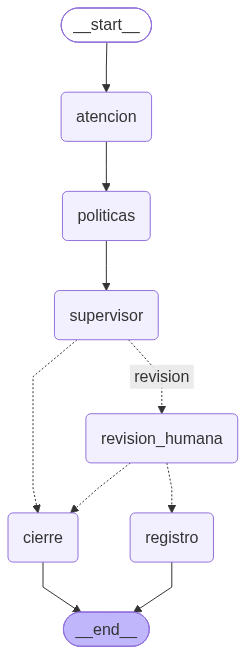

In [59]:
try:
    # draw_mermaid_png() usa un servicio web para dibujar; display(Image(...)) muestra el PNG.
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    # Si el servicio no responde, mostramos el mismo diagrama como texto Mermaid.
    print(app.get_graph().draw_mermaid())

## Paso 6 · ▶️ Iniciar una solicitud y observar la pausa
**Qué hace:**
1. Crea un pedido de demostración con un identificador único.
2. Crea un `config` con un `thread_id` nuevo: es la **llave** de esta solicitud. Guárdalo: lo necesitas para reanudar.
3. `invoke` ejecuta atención → políticas → supervisor → revisión humana y **se detiene** en `interrupt()`.
4. Comprueba que hay interrupción y que **no** existe reembolso.

**📥 Entrada:** `{"caso": caso_demo}` + `config`

**📤 Salida esperada:**
```
⏸ El grafo está en pausa esperando a una persona.
Payload para la persona:
{ "pregunta": "¿Apruebas esta propuesta de reembolso?", "caso": {...}, "analisis": {...},
  "propuesta": {"recomendacion": "reembolsar", "monto_cop": 450000, ...}, "supera_umbral": true, ... }
Siguiente nodo: ('revision_humana',)
¿Existe reembolso? False
```

> ⚠️ **No vuelvas a ejecutar esta celda para continuar**: crearía otra solicitud con otro `thread_id`.

🤔 **¿Terminó el caso porque la celda terminó?** No: el grafo sigue pausado en el checkpointer. Detente aquí y lee el payload antes de seguir.

#### 📖 Lectura guiada de la celda
| Fragmento | Qué hace |
|---|---|
| `{**CASO, "pedido": "DEMO-" + uuid4().hex[:8]}` | Copia del caso con un número de pedido único (8 caracteres aleatorios) |
| `config = {"configurable": {"thread_id": ...}}` | Formato que exige LangGraph: el `thread_id` va dentro de `"configurable"` |
| `app.invoke({"caso": caso_demo}, config=config)` | Ejecuta el grafo con el estado inicial; se detiene en `interrupt()` |
| `pausa.get("__interrupt__")` | Si el grafo se pausó, el resultado trae la clave especial `__interrupt__` |
| `assert condición, "mensaje"` | Garantiza lo que esperamos; si no se cumple, la celda falla con ese mensaje |
| `pausa["__interrupt__"][0].value` | `__interrupt__` es una **lista** de interrupciones; tomamos la primera y su `.value` = el payload |
| `app.get_state(config).next` | Tupla con el/los nodo(s) pendiente(s) de ese hilo |

In [68]:
caso_demo = {**CASO, "pedido": "DEMO-" + uuid4().hex[:8]}             # copia del caso con pedido único
print(caso_demo)
config = {"configurable": {"thread_id": "reembolso-" + uuid4().hex}}   # llave de ESTA solicitud

pausa = app.invoke({"caso": caso_demo}, config=config)    # corre hasta interrupt() y se detiene

# Si hubo pausa, el resultado incluye la clave especial "__interrupt__".
assert pausa.get("__interrupt__"), "Debe estar esperando a una persona"
assert caso_demo["pedido"] not in REGISTRO, "No puede haber reembolso antes de la decisión"

print("⏸ El grafo está en pausa esperando a una persona.\nPayload para la persona:")
# "__interrupt__" es una lista; [0] es la primera interrupción y .value es el dict que pasó interrupt()
print(json.dumps(pausa["__interrupt__"][0].value, indent=2, ensure_ascii=False))
print("Siguiente nodo:", app.get_state(config).next)      # ('revision_humana',)
print("¿Existe reembolso?", caso_demo["pedido"] in REGISTRO)

{'pedido': 'DEMO-2007119b', 'monto_cop': 450000, 'dias_desde_entrega': 5, 'solicitud': 'El cliente reporta un producto defectuoso y pide devolución'}
⏸ El grafo está en pausa esperando a una persona.
Payload para la persona:
{
  "pregunta": "¿Apruebas esta propuesta de reembolso?",
  "caso": {
    "pedido": "DEMO-2007119b",
    "monto_cop": 450000,
    "dias_desde_entrega": 5,
    "solicitud": "El cliente reporta un producto defectuoso y pide devolución"
  },
  "analisis": {
    "resumen": "El caso es elegible para devolución porque la solicitud se realizó dentro del plazo de 15 días y el monto supera el umbral de 300,000 COP.",
    "evidencias": [
      "Pedido: DEMO-2007119b",
      "Monto: 450000 COP",
      "Días desde entrega: 5",
      "Solicitud del cliente: devolución por producto defectuoso",
      "Plazo de política: 15 días",
      "Umbral de aprobación: 300000 COP"
    ],
    "incertidumbres": [
      "No se especifica el tipo de defecto ni el estado del producto al momento

## Paso 7 · ▶️ Inspeccionar el checkpoint: ¿dónde está esperando el caso?
**Qué hace:** consulta el estado guardado del hilo sin ejecutar nada.

| Expresión | Qué muestra |
|---|---|
| `app.get_state(config).values` | El estado guardado: qué campos ya se escribieron |
| `app.get_state(config).next` | El nodo pendiente de ejecutar |
| `app.get_state_history(config)` | Todos los checkpoints que se han guardado para este hilo |

**📤 Salida esperada:** campos `caso, atencion, politicas, propuesta` presentes; `decision_humana` y `resultado` **ausentes**; siguiente nodo `revision_humana`.

In [69]:
guardado = app.get_state(config)              # "foto" del último checkpoint de este hilo (no ejecuta nada)
print("Campos ya escritos:", list(guardado.values))                  # .values = el estado guardado
print("¿Hay decisión humana?", "decision_humana" in guardado.values)  # aún no: falta reanudar
print("Siguiente nodo:", guardado.next)                              # .next = dónde se quedó
# get_state_history devuelve todos los checkpoints (uno por paso); list(...) los materializa para contarlos
print("Checkpoints guardados para este hilo:", len(list(app.get_state_history(config))))

Campos ya escritos: ['caso', 'atencion', 'politicas', 'propuesta']
¿Hay decisión humana? False
Siguiente nodo: ('revision_humana',)
Checkpoints guardados para este hilo: 5


## Paso 8 · ✍️ Decidir como persona y reanudar
**Qué hace:** tú eres la persona revisora.
1. Lee el payload del paso 6: el monto **supera el umbral** y el defecto **no está verificado**.
2. Escribe tu decisión en `DECISION` (`"aprobar"` o `"rechazar"`), tu nombre en `REVISOR` y un motivo.
3. `Command(resume=RESPUESTA_HUMANA)` transporta tu respuesta; `config` recupera **el mismo hilo**.

🧠 `DECISION` empieza en `None` **a propósito**: si alguien ejecuta todo el notebook sin leer, el caso **no se aprueba solo**. Un sistema con humano en el bucle nunca debe tener la aprobación como valor por defecto.

| 📥 Si decides | 📤 Salida esperada |
|---|---|
| `"aprobar"` | `REEMBOLSO_SIMULADO_REGISTRADO` y el registro con tu nombre |
| `"rechazar"` | `CERRADO_SIN_REEMBOLSO`, motivo “Rechazado por …” y `Sin reembolso` |
| `None` (sin decidir) | Mensaje recordándote decidir; el caso **sigue pausado** |

> ⚠️ Una solicitud solo se reanuda una vez. Para probar la otra decisión, vuelve al paso 6 e inicia una nueva.

🤔 **¿Por qué no se registra el reembolso antes de `interrupt()`?** Porque el código anterior a la pausa se repite al reanudar.

#### 📖 Lectura guiada de la celda
| Fragmento | Qué hace |
|---|---|
| `if DECISION is None:` | Si aún no escribiste tu decisión, solo muestra un recordatorio; **no reanuda** |
| `elif not app.get_state(config).next:` | `next` vacío = el hilo ya terminó; no se puede reanudar dos veces |
| `Command(resume=RESPUESTA_HUMANA)` | “Sobre” que lleva tu respuesta al `interrupt()` pausado |
| `app.invoke(Command(...), config=config)` | Mismo `config` = mismo hilo: continúa la solicitud del paso 6 |
| `final.get("motivo_cierre", "—")` | Muestra el motivo si existe; si no (aprobación), muestra un guion |
| `REGISTRO.get(pedido, "Sin reembolso")` | Busca el reembolso; si no existe, devuelve el texto |

In [70]:
DECISION = None                 # ✍️ escribe "aprobar" o "rechazar" DESPUÉS de leer el payload
REVISOR = "Docente en Colab"    # ✍️ tu nombre (declarado, no autenticado)
MOTIVO = "Revisé el caso ficticio y la propuesta"   # ✍️ explica tu decisión

if DECISION is None:
    # Sin decisión explícita no se reanuda: la aprobación nunca es el valor por defecto.
    print("✋ Aún no decides. Escribe DECISION = 'aprobar' o 'rechazar' y vuelve a ejecutar esta celda.")
    print("   El caso sigue en pausa. Siguiente nodo:", app.get_state(config).next)
elif not app.get_state(config).next:
    # next vacío → el hilo ya llegó a END; una solicitud se reanuda una sola vez.
    print("Esta solicitud ya terminó. Inicia una nueva en el paso 6 para otra demostración.")
else:
    RESPUESTA_HUMANA = {"decision": DECISION, "revisor": REVISOR, "motivo": MOTIVO}
    # Command(resume=...) entrega RESPUESTA_HUMANA al interrupt() pausado de ESTE hilo (mismo config).
    final = app.invoke(Command(resume=RESPUESTA_HUMANA), config=config)
    print("Resultado:", final["resultado"])
    print("Motivo de cierre:", final.get("motivo_cierre", "—"))          # solo existe si se cerró
    print("Registro:", REGISTRO.get(caso_demo["pedido"], "Sin reembolso"))

Resultado: CERRADO_SIN_REEMBOLSO
Motivo de cierre: Rechazado por Ana: Revisé el caso ficticio y la propuesta
Registro: Sin reembolso


## Paso 9 · ▶️ ¿Qué código se repitió al reanudar?
**Qué hace:** muestra cuántas veces **empezó** `revision_humana` en el hilo de la demostración.

| Momento | 📤 Valor esperado del contador |
|---|---|
| Después del paso 6 (pausado) | `1` |
| Después de reanudar en el paso 8 | `2` ← el nodo se ejecutó **desde el principio** otra vez |

🧠 Si en lugar de un contador hubiera una llamada al LLM o un cobro antes de `interrupt()`, **se habría hecho dos veces**. Por eso los efectos van en nodos **posteriores** a la aprobación (`registro`).

In [49]:
hilo = config["configurable"]["thread_id"]              # el hilo de la demostración (paso 6)
veces = EJECUCIONES_REVISION.get(hilo, 0)               # cuántas veces EMPEZÓ revision_humana
estado_hilo = "pausado" if app.get_state(config).next else "terminado"
print(f"revision_humana empezó {veces} vez/veces en este hilo (hilo {estado_hilo}).")
if veces == 2:
    # 1 vez al pausar + 1 vez al reanudar: el nodo se ejecuta desde la primera línea.
    print("👉 Se ejecutó de nuevo desde la primera línea al reanudar.")

revision_humana empezó 1 vez/veces en este hilo (hilo pausado).


## Paso 10 · ▶️ Pruebas automatizadas del control
**Qué hace:** usa decisiones **automáticas de ejemplo** (*fixtures*) para comprobar el código. No sustituyen a una persona en la demostración: cada prueba crea **su propia solicitud** con su propio `thread_id`.

| # | Prueba | 📥 Entrada | 📤 Salida esperada |
|---|---|---|---|
| 1 | Espera | Iniciar y no responder | Sigue pausado en `revision_humana`; sin reembolso |
| 2 | Aprobación | `aprobar` | `REEMBOLSO_SIMULADO_REGISTRADO`; registro con el revisor |
| 3 | Idempotencia | Ejecutar `registrar` otra vez | El registro no crece |
| 4 | Rechazo | `rechazar` | `CERRADO_SIN_REEMBOLSO`; sin registro |
| 5 | Separación de hilos | Rechazo en otro hilo | La solicitud de la prueba 1 **sigue** pausada |
| 6 | Respuesta inválida | `{"decision": "tal vez"}` | `ValidationError`; sin registro |
| 7 | Fuera de plazo | 20 días desde la entrega | Cierra **sin pausa**; motivo “Fuera del plazo” |
| 8 | Guardrail de monto | Propuesta de 400.000 para pedido de 450.000 | `ValueError` |
| 9 | Solicitar información | `solicitar_informacion` con monto 0 | No lanza error; la ruta va a `cierre` |

🤔 **¿Que pasen estas pruebas demuestra la calidad de un LLM real?** No: prueban el **control** con respuestas simuladas.

#### 📖 Lectura guiada de la celda
Esta celda es la más densa. Está organizada en tres partes:

**1. Ayudantes**
| Fragmento | Qué hace |
|---|---|
| `def iniciar_prueba(**cambios)` | `**cambios` recoge argumentos con nombre en un dict. `iniciar_prueba(dias_desde_entrega=20)` → `cambios = {"dias_desde_entrega": 20}` |
| `{**CASO, "pedido": ..., **cambios}` | Caso base + pedido único + lo que la prueba quiera cambiar |
| `return caso, cfg, r` | Devuelve tres valores; se reciben como `caso_x, cfg_x, r = iniciar_prueba()` |
| `def responder(cfg, **respuesta)` | `responder(cfg, decision="aprobar", ...)` reanuda con `{"decision": "aprobar", ...}` |

**2. El registrador de resultados `prueba(numero, nombre, fn)`**
| Fragmento | Qué hace |
|---|---|
| `fn()` | Ejecuta la función de comprobación que le pasamos |
| `except Exception as exc` | Si **cualquier** `assert` falla (o hay otro error), se anota ❌ con el motivo en lugar de detener el notebook |

**3. Cada prueba = preparar + `def pN(): assert ...` + `prueba(N, nombre, pN)`**
| Fragmento | Qué hace |
|---|---|
| `def p1(): ...` | Función pequeña con las comprobaciones; se define y se pasa a `prueba()` sin paréntesis |
| `try: ... except ValidationError: pass else: raise AssertionError(...)` | Prueba 6: **esperamos** un error. Si llega, `pass` (bien); si no llega, `else` lanza el fallo |
| `return` dentro de `except` (prueba 8) | Llegó el error esperado: la prueba termina bien |

In [50]:
# ── 1. Ayudantes ─────────────────────────────────────────────────────────────
def iniciar_prueba(**cambios):
    # Crea una solicitud NUEVA (pedido y thread_id únicos) y la ejecuta hasta la pausa o el final.
    # **cambios permite modificar el caso: iniciar_prueba(dias_desde_entrega=20)
    caso = {**CASO, "pedido": "TEST-" + uuid4().hex[:8], **cambios}
    cfg = {"configurable": {"thread_id": uuid4().hex}}
    r = app.invoke({"caso": caso}, config=cfg)
    return caso, cfg, r                       # tres valores: el caso, su config y el resultado

def responder(cfg, **respuesta):
    # Reanuda el hilo `cfg` con la respuesta: responder(cfg, decision="aprobar", revisor=..., motivo=...)
    return app.invoke(Command(resume=respuesta), config=cfg)

# ── 2. Registrador de resultados ─────────────────────────────────────────────
resultados = []
def prueba(numero, nombre, fn):
    # Ejecuta la función de comprobación `fn` y anota ✅ o ❌ sin detener el notebook.
    try:
        fn()
        resultados.append({"#": numero, "prueba": nombre, "resultado": "✅"})
    except Exception as exc:                  # un assert que falla lanza AssertionError
        resultados.append({"#": numero, "prueba": nombre, "resultado": f"❌ {type(exc).__name__}: {exc}"})

# ── 3. Pruebas: preparar → definir comprobaciones → registrar ────────────────

# 1 · Espera: se inicia y nadie responde
caso_espera, cfg_espera, r = iniciar_prueba()
def p1():
    assert r.get("__interrupt__"), "no se pausó"
    assert app.get_state(cfg_espera).next == ("revision_humana",)    # sigue esperando a la persona
    assert caso_espera["pedido"] not in REGISTRO                     # y no hay reembolso
prueba(1, "Sin respuesta: sigue pausado, sin reembolso", p1)        # p1 sin paréntesis: se pasa la función

# 2 y 3 · Aprobación e idempotencia
caso_ok, cfg_ok, _ = iniciar_prueba()         # "_" = valor que no vamos a usar
final_ok = responder(cfg_ok, decision="aprobar", revisor="fixture", motivo="prueba aprobación")
def p2():
    assert final_ok["resultado"] == "REEMBOLSO_SIMULADO_REGISTRADO"
    assert REGISTRO[caso_ok["pedido"]]["revisor"] == "fixture"
    assert not app.get_state(cfg_ok).next, "el hilo debería haber terminado"
prueba(2, "Aprobación registra reembolso simulado", p2)
def p3():
    antes = len(REGISTRO)
    registrar(final_ok)                       # ejecutamos el efecto OTRA vez a propósito
    assert len(REGISTRO) == antes             # setdefault evitó el duplicado
prueba(3, "Idempotencia local del registro", p3)

# 4 y 5 · Rechazo y separación de hilos
caso_no, cfg_no, _ = iniciar_prueba()
final_no = responder(cfg_no, decision="rechazar", revisor="fixture", motivo="evidencia insuficiente")
def p4():
    assert final_no["resultado"] == "CERRADO_SIN_REEMBOLSO"
    assert final_no["motivo_cierre"].startswith("Rechazado por fixture")
    assert caso_no["pedido"] not in REGISTRO
prueba(4, "Rechazo cierra sin reembolso", p4)
def p5():
    # Lo que pasó en otros hilos no debe afectar a la solicitud de la prueba 1
    assert app.get_state(cfg_espera).next == ("revision_humana",), "otro hilo afectó a la prueba 1"
    assert caso_espera["pedido"] not in REGISTRO
prueba(5, "Separación de hilos", p5)

# 6 · Respuesta humana inválida: ESPERAMOS un ValidationError
caso_bad, cfg_bad, _ = iniciar_prueba()
def p6():
    try:
        responder(cfg_bad, decision="tal vez")    # sin revisor ni motivo, y con un valor no permitido
    except ValidationError:
        pass                                      # ✔ llegó el error esperado
    else:
        raise AssertionError("debió rechazar una respuesta humana inválida")   # solo si NO hubo error
    assert caso_bad["pedido"] not in REGISTRO
prueba(6, "Respuesta inválida no registra reembolso", p6)

# 7 · Fuera de plazo: el grafo termina sin pausa
caso_tarde, cfg_tarde, final_tarde = iniciar_prueba(dias_desde_entrega=20)
def p7():
    assert not final_tarde.get("__interrupt__"), "no debería pedir revisión humana"
    assert final_tarde["resultado"] == "CERRADO_SIN_REEMBOLSO"
    assert final_tarde["motivo_cierre"] == "Fuera del plazo de la política"
    assert caso_tarde["pedido"] not in REGISTRO
prueba(7, "Fuera de plazo: cierre sin pausa ni registro", p7)

# 8 · Guardrail de monto: ESPERAMOS un ValueError
def p8():
    try:
        verificar_monto({"recomendacion": "reembolsar", "monto_cop": 400000}, CASO)
    except ValueError:
        return                                    # ✔ llegó el error esperado: la prueba termina bien
    raise AssertionError("debió detener un monto distinto al del pedido")
prueba(8, "Guardrail: monto distinto detiene el flujo", p8)

# 9 · Solicitar información NO es un error
def p9():
    propuesta = {"recomendacion": "solicitar_informacion", "monto_cop": 0, "justificacion": "faltan fotos"}
    verificar_monto(propuesta, CASO)              # no debe lanzar
    assert ruta_propuesta({"caso": CASO, "propuesta": propuesta}) == "cierre"
prueba(9, "Solicitar información: sin error, ruta a cierre", p9)

display(pd.DataFrame(resultados))
# sum(...) cuenta cuántas filas tienen ✅ (True vale 1, False vale 0)
print(f"{sum(r['resultado'] == '✅' for r in resultados)}/{len(resultados)} pruebas correctas")

,#,prueba,resultado
0,1,"Sin respuesta: sigue pausado, sin reembolso",✅
1,2,Aprobación registra reembolso simulado,✅
2,3,Idempotencia local del registro,✅
3,4,Rechazo cierra sin reembolso,✅
4,5,Separación de hilos,✅
5,6,Respuesta inválida no registra reembolso,✅
6,7,Fuera de plazo: cierre sin pausa ni registro,✅
7,8,Guardrail: monto distinto detiene el flujo,✅
8,9,"Solicitar información: sin error, ruta a cierre",✅


9/9 pruebas correctas


## ⚠️ Errores frecuentes
| Síntoma | Causa | Qué hacer |
|---|---|---|
| `KeyError: '__interrupt__'` en el paso 6 | El grafo no se pausó (p. ej., caso fuera de plazo) | Revisar `dias_desde_entrega` y la propuesta |
| El paso 8 dice “ya terminó” | Esa solicitud ya se reanudó | Iniciar una nueva en el paso 6 |
| El paso 8 no hace nada | `DECISION` sigue en `None` | Escribir `"aprobar"` o `"rechazar"` |
| Se pierden los casos pausados | Se reinició el runtime de Colab | `InMemorySaver` no es durable; volver a iniciar |
| `ValidationError` en modo real | El LLM devolvió JSON fuera del esquema | Es el comportamiento esperado: el flujo se detiene antes de autorizar |
| Error “checkpointer” al reanudar | Se compiló sin `checkpointer=` | Compilar como en el paso 4.4 |

## Paso 11 · Transferencia al reto de pagos
**Discusión guiada:** cómo llevar este mecanismo al notebook 01. No hay código pendiente en este notebook.

1. Conserva intacta tu entrega 01; trabaja en una **copia de evolución**.
2. Sustituye el marcador `PENDIENTE` por un nodo con `interrupt()`.
3. Presenta a la persona el incidente, el plan del supervisor, los riesgos y la evidencia.
4. Compila con checkpointer y usa **un `thread_id` por incidente**.
5. Reanuda con aprobar o rechazar y verifica **ambas** rutas. No ejecutes acciones reales.
6. Entrega evidencia de espera, aprobación y rechazo; explica qué cambia si Colab se reinicia.

**Esqueleto orientativo** (no se ejecuta aquí):
```python
class AprobacionPagos(BaseModel):
    model_config = ConfigDict(extra="forbid")
    decision: Literal["aprobar", "rechazar"]
    revisor: str = Field(min_length=1)
    motivo: str = Field(min_length=1)

def revision_humana(e):
    respuesta = interrupt({"incidente": e["incidente"], "plan": e["decision"],
                           "riesgos": e["riesgos"], "auditoria": e["auditoria"]})
    return {"aprobacion": AprobacionPagos.model_validate(respuesta).model_dump(),
            "bitacora": e["bitacora"] + ["revision_humana"]}

app = builder.compile(checkpointer=InMemorySaver())
config = {"configurable": {"thread_id": "incidente-" + uuid4().hex}}
```

**Preguntas de cierre:**
- ¿Quién puede aprobar? ¿Cómo sabríamos que es quien dice ser?
- ¿Qué propuesta **exacta** aprobó? ¿Qué ocurre si cambia el monto o el plan después?
- ¿Qué código se repite al reanudar?
- ¿Qué valida Pydantic y qué sigue sin garantizar?

## Fuentes y límites
Implementación original basada en la documentación oficial, consultada el 21-10-2026:
- [LangGraph: interrupts](https://docs.langchain.com/oss/python/langgraph/interrupts)
- [Referencia interrupt](https://reference.langchain.com/python/langgraph/types/interrupt)
- [Persistencia](https://docs.langchain.com/oss/python/langgraph/persistence)
- [Pydantic: models](https://docs.pydantic.dev/latest/concepts/models/)

**Límites de esta demo:** registro y checkpoints en memoria; identidad del revisor **declarada**, no autenticada; sin pagos ni persistencia entre reinicios. El registro evita duplicados por pedido **en este proceso**, no garantiza ejecución exactamente una vez en un sistema distribuido. Si la propuesta se edita después de aprobarla, debe solicitarse nueva autorización. Las pruebas simuladas no evalúan respuestas reales de Groq.